# Week 11 — Block 2: Guided Demo (Consuming APIs & Data Endpoints)

**DATS 6401 · Visualization of Complex Data**

Five parts, ~70 minutes.

| Part | Minutes | What it teaches |
|---|---|---|
| **A** — USGS earthquakes | ~18 | the four-step pattern, and query parameters as the interface |
| **B** — when a 200 is not a success | ~16 | why checking the status code is not enough |
| **C** — the course endpoint | ~10 | two processes, and a deliberate 404 |
| **D** — APIs that need a key | ~18 | headers, auth, and two vendors compared |
| **E** — into Streamlit | ~8 | caching, and failing gracefully |

Parts A, B and D need internet. Part C needs `course_endpoint.py` running in a
second terminal. Part D is an instructor demo and needs an Anthropic key, an OpenAI key,
or either one; every cell skips itself when its key is missing.

---
## Part A — a real API, start to finish (~15 min)

The USGS earthquake catalog is public, needs no key, and takes query parameters
that actually change the question. Every API call has the same four moving
parts: a **URL**, **query parameters**, a **timeout**, and a **status check**.

In [1]:
import requests
import pandas as pd
from datetime import date, timedelta

# Relative dates, not hardcoded ones. A notebook with starttime="2026-10-01"
# written into it quietly becomes a notebook about last year.
end = date.today()
start = end - timedelta(days=30)

r = requests.get(
    "https://earthquake.usgs.gov/fdsnws/event/1/query",   # the endpoint
    params={                                              # the query parameters
        "format": "geojson",
        "starttime": start.isoformat(),
        "endtime": end.isoformat(),
        "minmagnitude": 5,
    },
    timeout=20,                                           # never call without one
)

print("Status:", r.status_code)
print("Content-Type:", r.headers["content-type"])
r.raise_for_status()                                      # raises on 4xx/5xx

payload = r.json()                                        # JSON -> dicts and lists
print("Top-level keys:", list(payload))
print("Events returned:", payload["metadata"]["count"])

/opt/anaconda3/envs/dataviz/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Status: 200
Content-Type: application/json; charset=utf-8
Top-level keys: ['type', 'metadata', 'features', 'bbox']
Events returned: 209


**Narrate:** *request → check status → parse JSON → DataFrame.* Everything else
this week is a variation on those four steps.

Now the parsing, which is where the geography from Weeks 9 and 10 comes back.

In [2]:
# GeoJSON is nested: each event is a Feature with `properties` and `geometry`.
#
# The coordinates are [longitude, latitude, depth_km]. Longitude comes FIRST --
# the opposite of how we say it out loud -- and there is a third number that
# most code does not expect. Unpack the three deliberately; `lat, lon = coords`
# would silently swap the hemisphere and then crash on the extra value.
rows = []
for f in payload["features"]:
    lon, lat, depth = f["geometry"]["coordinates"]
    p = f["properties"]
    rows.append({
        # USGS gives time as epoch MILLISECONDS, not an ISO string.
        "time": pd.to_datetime(p["time"], unit="ms", utc=True),
        "mag": p["mag"],
        "place": p["place"],
        "lon": lon, "lat": lat, "depth_km": depth,
    })

quakes = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)
print(quakes.shape)
quakes.head()

(209, 6)


,time,mag,place,lon,lat,depth_km
0,2026-10-05 01:18:50.490000+00:00,5.3,central Mid-Atlantic Ridge,-19.9285,-0.4417,10.000
1,2026-10-05 05:26:45.292000+00:00,5.0,"67 km E of ‘Ohonua, Tonga",-174.3041,-21.3012,10.000
2,2026-10-05 10:52:09.874000+00:00,5.0,"183 km ENE of Saipan, Northern Mariana Islands",147.3450,15.8212,10.000
3,2026-10-05 20:22:59.107000+00:00,5.0,south of the Fiji Islands,179.8632,-24.4774,518.391
4,2026-10-06 13:11:22.940000+00:00,5.0,"43 km NNE of Semporna, Malaysia",118.7737,4.8423,10.000


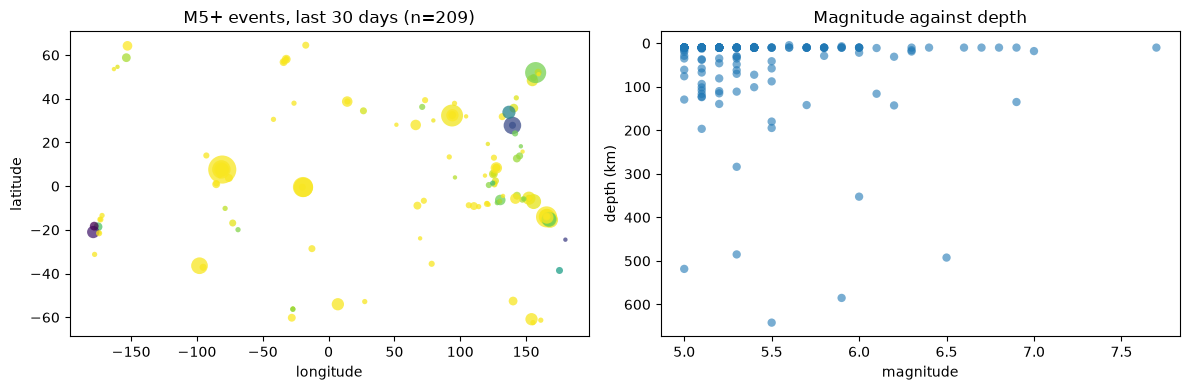

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Marker size is an AREA, so it goes as the square -- the same point the Altair
# `size` channel made in Week 10.
ax1.scatter(quakes.lon, quakes.lat, s=(quakes.mag - 4.5) ** 2 * 40,
            c=quakes.depth_km, cmap="viridis_r", alpha=0.75, edgecolor="none")
ax1.set(xlabel="longitude", ylabel="latitude",
        title=f"M5+ events, last 30 days (n={len(quakes)})")

ax2.scatter(quakes.mag, quakes.depth_km, alpha=0.6, edgecolor="none")
ax2.invert_yaxis()          # depth increases downward
ax2.set(xlabel="magnitude", ylabel="depth (km)", title="Magnitude against depth")

plt.tight_layout()

That left panel is a world map drawn with no projection and no basemap, which is
exactly what Week 9 warned about — plotting raw degrees on a flat grid. It is
legible enough to check the data arrived, and it is not a map you would ship.

**The query parameters are the interface.** Changing one changes the question,
and this is what a widget gets wired to later.

In [4]:
for m in (5.0, 5.5, 6.0, 6.5):
    q = requests.get(
        "https://earthquake.usgs.gov/fdsnws/event/1/query",
        params={"format": "geojson", "starttime": start.isoformat(),
                "endtime": end.isoformat(), "minmagnitude": m},
        timeout=20,
    )
    q.raise_for_status()
    print(f"minmagnitude={m}: {q.json()['metadata']['count']:>4} events")

minmagnitude=5.0:  209 events
minmagnitude=5.5:   53 events
minmagnitude=6.0:   22 events
minmagnitude=6.5:    8 events


---
## Part B — when a 200 is not a success (~12 min)

`raise_for_status()` is necessary and not sufficient. A 200 means the server
received your request and chose to answer. It does not promise the answer is
your data.

Three live examples, all true as of today, each failing a different way.

### 1. Valid JSON, wrong shape

In [ ]:
# This exact call was in last year's materials and worked for years.
r = requests.get("https://restcountries.com/v3.1/region/americas",
                 params={"fields": "name,population,area"}, timeout=15)

print("Status:", r.status_code)                      # 200
print("Content-Type:", r.headers["content-type"])    # application/json
r.raise_for_status()                                 # passes
r.json()

In [ ]:
# Status checked, body is valid JSON. Here is last year's parsing line, unchanged:
try:
    df = pd.DataFrame([{"country": c["name"]["common"],
                        "population": c["population"]} for c in r.json()])
except TypeError as e:
    print("TypeError:", e)

# Iterating a dict yields its KEYS, so `c` is the string "success" and
# c["name"] indexes a string with a string. Notice what the error does NOT say:
# it names no API, no deprecation, no status -- it points at a line that has
# been correct for years.
print()
print("r.json() is a:", type(r.json()).__name__, "with keys", list(r.json()))

### 2. A 200 that is not JSON at all

In [ ]:
# The Census ACS API used to answer small requests without a key. It now
# returns 200 -- and an HTML page.
r2 = requests.get("https://api.census.gov/data/2023/acs/acs5",
                  params={"get": "NAME,B01001_001E", "for": "state:*"}, timeout=20)

print("Status:", r2.status_code, "| Content-Type:", r2.headers["content-type"])
try:
    r2.json()
except requests.exceptions.JSONDecodeError as e:
    print("JSONDecodeError:", e)
print()
print(r2.text[:120])

### 3. A real error whose body is not JSON either

In [ ]:
# USGS does return a proper 4xx for a bad parameter -- but the body is plain
# text, so the obvious way to read the error message fails too.
r3 = requests.get("https://earthquake.usgs.gov/fdsnws/event/1/query",
                  params={"format": "geojson", "minmagnitude": "banana"}, timeout=20)

print("Status:", r3.status_code, "| Content-Type:", r3.headers["content-type"])
try:
    r3.json()
except requests.exceptions.JSONDecodeError:
    print("r3.json() raised. Read r3.text instead:")
    print(r3.text[:170])

**Narrate:** three failures, three different layers.

| | Status | Content-Type | Parsed | What broke |
|---|---|---|---|---|
| REST Countries | 200 | `application/json` | a `dict` | the **shape** |
| Census | 200 | `text/html` | raises | the **content type** |
| USGS bad param | 400 | `text/plain` | raises | the status — and the error body is not JSON |

So the check is three checks, not one. A helper that refuses to hand back
anything we did not ask for moves every one of these failures to the line that
caused it.

In [5]:
def get_json(url, params=None, timeout=20, expect=dict):
    """Fetch JSON, or raise where the problem actually is.

    Three checks, because the three examples above failed three different ways:
    the status, the content type, and the shape of the parsed body.
    """
    r = requests.get(url, params=params, timeout=timeout)
    r.raise_for_status()                                      # 1. status

    ctype = r.headers.get("content-type", "")
    if "json" not in ctype:                                   # 2. content type
        raise ValueError(f"expected JSON, got {ctype!r}: {r.text[:120]}")

    payload = r.json()
    if not isinstance(payload, expect):                       # 3. shape
        raise ValueError(f"expected {expect.__name__}, got "
                         f"{type(payload).__name__}: {str(payload)[:140]}")
    return payload


checks = [
    ("USGS",           "https://earthquake.usgs.gov/fdsnws/event/1/query",
     {"format": "geojson", "starttime": start.isoformat(), "minmagnitude": 6}, dict),
    ("REST Countries", "https://restcountries.com/v3.1/region/americas",
     {"fields": "name,population"}, list),
    ("Census",         "https://api.census.gov/data/2023/acs/acs5",
     {"get": "NAME", "for": "state:*"}, list),
]

for label, url, params, expect in checks:
    try:
        out = get_json(url, params, expect=expect)
        n = out["metadata"]["count"] if isinstance(out, dict) and "metadata" in out else len(out)
        print(f"{label:16s} ok   -> {type(out).__name__}, {n}")
    except Exception as e:
        print(f"{label:16s} FAIL -> {type(e).__name__}: {str(e)[:110]}")

USGS             ok   -> dict, 22
REST Countries   FAIL -> ValueError: expected list, got dict: {'success': False, 'data': None, 'errors': [{'message': 'This API version has been de
Census           FAIL -> ValueError: expected JSON, got 'text/html': <html style="font-size: 14px;">

<head>
    <title>Missing Key</title>
    <li


**The lesson to say out loud:** an API that changes under you does not announce
it. REST Countries still answers, still returns 200, still returns JSON — and
every notebook that depended on it broke silently. The three checks are what
turn that into an error message you can act on.

---
## Part C — the course endpoint: two processes (~10 min)

Everything so far called somebody else's server. Now run your own, so that
"client and server are separate processes" is something you have done rather
than been told. Next week you write what the server does; this week you only
start it.

In a **second terminal**, from this folder:

```bash
uvicorn course_endpoint:app --port 8001
```

Leave it running. It prints every request it receives — worth putting that
terminal next to this notebook so the class can watch the two halves talk.

In [ ]:
BASE = "http://127.0.0.1:8001"

# Check it is alive before anything else. A health endpoint exists so a client
# can answer "is the server up?" without asking for real data.
print(get_json(f"{BASE}/health"))
print(get_json(f"{BASE}/"))

In [ ]:
payload = get_json(f"{BASE}/data", params={"species": "setosa"})
print("Count:", payload["count"])
pd.DataFrame(payload["records"]).head(3)

In [ ]:
# Now break it on purpose: the endpoint 404s on an unknown species.
r = requests.get(f"{BASE}/data", params={"species": "dragon"}, timeout=5)
print("Status:", r.status_code)        # 404
print("Body:", r.json())               # FastAPI's errors ARE json: {"detail": ...}

try:
    r.raise_for_status()
except requests.HTTPError as e:
    print("Caught:", e)

**Narrate:** a non-200 is not an exception until *you* make it one.
`raise_for_status()` inside `try/except` is the discipline, and a client that
crashes on a 404 is a broken client.

Note the contrast with Part B: FastAPI returns its errors as JSON
(`{"detail": ...}`), so `r.json()` works on the failure here. USGS returned
plain text. You cannot assume either — which is why the helper checks.

---
## Part D — APIs that need a key (~12 min)

*Instructor demo. The cells skip themselves if a key is missing, so this
notebook still runs end to end without either one.*

Everything so far was a `GET` with the whole request in the URL. A model API is
the other shape, and it brings in the one part of an HTTP request this course
has not used yet:

| | USGS and the course endpoint | a model API |
|---|---|---|
| method | `GET` | `POST` |
| the request lives in | the URL's query string | a JSON **body** |
| who you are | nobody — it is public | an **auth header** |
| what a 200 guarantees | less than you think | even less |

We call **two vendors**, because the useful skill is not either one's syntax.
The four steps never change; what changes between vendors is the name of the
header and the shape of the reply, and the only way to learn those is to read
the docs and print the response.

In [ ]:
import os
import time
import requests

ANTHROPIC = bool(os.environ.get("ANTHROPIC_API_KEY"))
OPENAI    = bool(os.environ.get("OPENAI_API_KEY"))

# Keys come from the environment, never from the notebook. A key pasted into a
# cell is a key committed to git and published with the course site.
#
#   export ANTHROPIC_API_KEY=...        (macOS / Linux; setx on Windows)
#   export OPENAI_API_KEY=...
#
# Flagship models on both sides, so the comparison later is fair. For a demo
# you run repeatedly, swap in the cheap tier -- and note that the two vendors
# price it identically, at $0.10 and $0.50 per million tokens:
#     CLAUDE_MODEL, CLAUDE_PRICE = "claude-haiku-5-5", (0.10, 0.50)
#     GPT_MODEL,    GPT_PRICE    = "gpt-6-luna",       (0.10, 0.50)
CLAUDE_MODEL, CLAUDE_PRICE = "claude-opus-5-5", (4.00, 20.00)   # USD per 1M in/out
GPT_MODEL,    GPT_PRICE    = "gpt-6-astra",     (10.00, 50.00)

PROMPT = ("In one sentence, what does the USGS earthquake API return "
          "when you ask for format=geojson?")

print(f"Anthropic key: {'found' if ANTHROPIC else 'MISSING -- those cells will skip'}")
print(f"OpenAI key:    {'found' if OPENAI else 'MISSING -- those cells will skip'}")

### The raw calls, so the header is visible

We would normally use each vendor's own library, and we will in a moment. The
plain `requests` version comes first because the **headers** are the point of
this part, and a library's whole job is to hide them.

Both vendors authenticate the same way — `Authorization: Bearer <key>` — which
is worth noticing: it is an HTTP convention, not a vendor's invention. The
difference is a header OpenAI does not have at all.

In [ ]:
if ANTHROPIC:
    t0 = time.perf_counter()
    r = requests.post(
        "https://api.anthropic.com/v1/messages",
        headers={
            # Same convention OpenAI uses. Anthropic also accepts x-api-key,
            # but that is a legacy fallback now, not the primary.
            "Authorization": f"Bearer {os.environ['ANTHROPIC_API_KEY']}",
            # Required, and the thing OpenAI has no equivalent of: it pins the
            # request format, so an old client keeps working when the API moves.
            "anthropic-version": "2026-10-21",
            "content-type": "application/json",
        },
        json={"model": CLAUDE_MODEL,
              "max_tokens": 400,
              "messages": [{"role": "user", "content": PROMPT}]},
        timeout=90,                 # models are slow; a 10s timeout will fire
    )
    claude_secs = time.perf_counter() - t0
    print("Status:", r.status_code, f"| {claude_secs:.1f}s")
    r.raise_for_status()

    body = r.json()
    print("Top-level keys:", list(body))        # print it before assuming a shape
    print("stop_reason:", body["stop_reason"])
    print("usage:", body["usage"])
    print()
    print("".join(b["text"] for b in body["content"] if b["type"] == "text"))
else:
    print("skipped: no ANTHROPIC_API_KEY")

In [ ]:
def gpt_text(body):
    """Pull the text out of a Responses-API body.

    The reply is a list of typed items, not a string. On this model the list
    comes back as ['reasoning', 'message'] -- so output[0] is NOT your answer,
    it is the model's reasoning item. Walk the list and take the text parts
    rather than indexing [0] and hoping.
    """
    out = []
    for item in body.get("output", []):
        for part in item.get("content", []) or []:
            if part.get("type") == "output_text":
                out.append(part.get("text", ""))
    return "".join(out)


if OPENAI:
    t0 = time.perf_counter()
    r = requests.post(
        "https://api.openai.com/v1/responses",
        headers={
            "Authorization": f"Bearer {os.environ['OPENAI_API_KEY']}",
            "content-type": "application/json",   # and no version header
        },
        json={"model": GPT_MODEL,
              "input": PROMPT,                 # "input", where Anthropic took "messages"
              "max_output_tokens": 400},       # and "max_output_tokens", not "max_tokens"
        timeout=90,
    )
    gpt_secs = time.perf_counter() - t0
    print("Status:", r.status_code, f"| {gpt_secs:.1f}s")
    r.raise_for_status()

    body = r.json()
    print("Top-level keys:", list(body))
    print("status:", body.get("status"), "| incomplete_details:", body.get("incomplete_details"))
    print("usage:", body.get("usage"))
    print()
    print(gpt_text(body))
else:
    print("skipped: no OPENAI_API_KEY")

### Same four steps, two sets of names

| | Anthropic | OpenAI |
|---|---|---|
| endpoint | `/v1/messages` | `/v1/responses` |
| auth header | `Authorization: Bearer ...` | `Authorization: Bearer ...` |
| version header | `anthropic-version`, required | none |
| the prompt goes in | `messages` | `input` |
| output cap | `max_tokens` | `max_output_tokens` |
| where the text is | `content[]`, `type == "text"` | `output[].content[]`, `type == "output_text"` |
| "why did it stop" | `stop_reason` | `status` + `incomplete_details.reason` |
| token counts | `usage.input_tokens` / `output_tokens` | `usage.input_tokens` / `output_tokens` |

**Narrate:** one row of that table is a concept — `anthropic-version` is API
versioning, which is how an endpoint changes without breaking the clients
already calling it. Pin a version and your code keeps working; omit one, as
OpenAI requires you to, and you inherit whatever the API does next. The rest of
the table is vocabulary, and it is all in each vendor's docs. The transferable skill is the one from Part A — call
it, print the top-level keys, find where your data actually lives — and it is
the same skill whether the endpoint belongs to the USGS or to OpenAI.

### Through the SDKs

What you would actually ship. Each library does the retries, the timeouts, the
typed errors and the parsing — but it is the same request, and you should be
able to point at every piece of it in the cells above.

```bash
pip install anthropic openai
```

::: {.callout-important}
If an SDK call dies with `APIConnectionError: Connection error.` while the raw
`requests` calls above work fine, it is not your network. Anaconda ships
`Brotli 1.0.9`; both SDKs' HTTP layer calls a newer Brotli API, so the
*response* fails to decompress and the error names the wrong cause entirely.

```bash
pip install -U Brotli
```
:::

In [ ]:
if ANTHROPIC:
    import anthropic
    claude = anthropic.Anthropic()          # reads ANTHROPIC_API_KEY itself
    msg = claude.messages.create(
        model=CLAUDE_MODEL, max_tokens=400,
        messages=[{"role": "user", "content": PROMPT}])
    print("Anthropic:", msg.stop_reason)
    print(next(b.text for b in msg.content if b.type == "text")[:200])

print()

if OPENAI:
    from openai import OpenAI
    gpt = OpenAI()                          # reads OPENAI_API_KEY itself
    resp = gpt.responses.create(
        model=GPT_MODEL, input=PROMPT, max_output_tokens=400)
    print("OpenAI:", resp.status)
    print(resp.output_text[:200])           # the library's convenience helper

if not (ANTHROPIC or OPENAI):
    print("skipped: no keys")

### Part B again, one level up

Both vendors hand you a 200 in situations that are not success. The commonest
is a **truncated** answer: you capped the output, the model ran into the cap,
and what you get back is a sentence that stops mid-word. HTTP 200, valid JSON,
right shape, unusable content — and nothing raises.

Each vendor tells you, in its own field:

In [ ]:
CUT = "List every US state and its capital."

if ANTHROPIC:
    cut = claude.messages.create(model=CLAUDE_MODEL, max_tokens=64,
                                 messages=[{"role": "user", "content": CUT}])
    text = "".join(b.text for b in cut.content if b.type == "text")
    print("Anthropic stop_reason:", cut.stop_reason)        # expect max_tokens
    print("  text:", repr(text[-70:]) if text else "(none -- the cap was spent before any text)")

if OPENAI:
    cut2 = gpt.responses.create(model=GPT_MODEL, input=CUT, max_output_tokens=64)
    print("OpenAI status:", cut2.status,                    # expect incomplete
          "| reason:", getattr(cut2.incomplete_details, "reason", None))
    print("  text:", repr(cut2.output_text[-70:]) if cut2.output_text else "(none)")

if ANTHROPIC or OPENAI:
    print()
    print("Nothing raised. A client that trusts either answer ships a truncated")
    print("list to its user and never finds out.")
else:
    print("skipped: no keys")

### What there is to visualize

The *content* of a model reply is prose, which is not this course's problem.
The *call* is: it has a latency, a token count and a price, and those are
numbers that belong on a chart.

Headline rates do not settle which is cheaper. At the cheap tier the two
vendors charge exactly the same ($0.10 in, $0.50 out per million tokens), so
what separates them on a real task is how many tokens they spend and how long
they take — which you can only find out by measuring.

There is a second thing worth measuring, and it is invisible in the reply: both
models spend output tokens **thinking** before they answer, and you pay output
rates for every one of them. One run of the question above billed 206 output
tokens of which 88 were thinking — 43% of the output cost, for text that never
reaches the page. The chart below splits it out.

In [ ]:
import matplotlib.pyplot as plt

QUESTIONS = {
    "short":  "Name one thing an API returns.",
    "medium": PROMPT,
    "long":   "Explain in three short paragraphs why a client should check the "
              "content type of a response and not only its status code.",
}

runs = []
for label, q in QUESTIONS.items():
    if ANTHROPIC:
        t0 = time.perf_counter()
        m = claude.messages.create(model=CLAUDE_MODEL, max_tokens=700,
                                   messages=[{"role": "user", "content": q}])
        det = getattr(m.usage, "output_tokens_details", None)
        runs.append({"vendor": "Anthropic", "prompt": label,
                     "seconds": round(time.perf_counter() - t0, 2),
                     "in_tok": m.usage.input_tokens,
                     "out_tok": m.usage.output_tokens,
                     "hidden_tok": getattr(det, "thinking_tokens", 0) or 0,
                     "in_rate": CLAUDE_PRICE[0], "out_rate": CLAUDE_PRICE[1]})
    if OPENAI:
        t0 = time.perf_counter()
        o = gpt.responses.create(model=GPT_MODEL, input=q, max_output_tokens=700)
        det = getattr(o.usage, "output_tokens_details", None)
        runs.append({"vendor": "OpenAI", "prompt": label,
                     "seconds": round(time.perf_counter() - t0, 2),
                     "in_tok": o.usage.input_tokens,
                     "out_tok": o.usage.output_tokens,
                     "hidden_tok": getattr(det, "reasoning_tokens", 0) or 0,
                     "in_rate": GPT_PRICE[0], "out_rate": GPT_PRICE[1]})

if runs:
    usage = pd.DataFrame(runs)
    usage["visible_tok"] = usage.out_tok - usage.hidden_tok
    usage["cost_usd"] = (usage.in_tok / 1e6 * usage.in_rate
                         + usage.out_tok / 1e6 * usage.out_rate).round(6)
    usage["label"] = usage.vendor.str.slice(0, 4) + "/" + usage.prompt
    display(usage[["vendor", "prompt", "seconds", "in_tok",
                   "visible_tok", "hidden_tok", "cost_usd"]])

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

    # Output tokens, split into the part you can read and the part you cannot.
    usage.set_index("label")[["visible_tok", "hidden_tok"]].plot.bar(
        stacked=True, ax=axes[0], title="Output tokens: visible vs thinking",
        color=["#4878a8", "#d9534f"])
    axes[0].set_xlabel("")

    for ax, col, title in zip(axes[1:], ["seconds", "cost_usd"],
                              ["Latency (s)", "Cost (USD)"]):
        usage.pivot(index="prompt", columns="vendor", values=col).plot.bar(ax=ax, title=title)
        ax.set_xlabel("")
    plt.tight_layout()

    hidden_share = usage.hidden_tok.sum() / max(usage.out_tok.sum(), 1)
    print(f"\nTotal spent on this demo: ${usage.cost_usd.sum():.5f}")
    print(f"Billed output tokens you never see: {hidden_share:.0%}")
else:
    print("skipped: no keys")

**Narrate:** output tokens dominate the bill — they cost five times what input
tokens do on both vendors — latency tracks how much the model *writes* rather
than how long your prompt was, and a sizeable slice of what you pay for is
thinking you never read. All three are visible in the chart and none of them is
obvious from a price list. This is the argument for measuring rather than
estimating, and it is the same argument Part A made about printing a response
before assuming its shape.

That is also the argument for `@st.cache_data` in the next part, stated in
dollars and seconds rather than as advice. It answers the question students ask
every year: *why cache at all?* A USGS call is free and takes a quarter of a
second. A model call costs money and takes seconds. The same decorator covers
both, and the second one is where it pays for itself.

---
## Part E — the same calls inside Streamlit (~4 min)

Open `client_starter.py` and run it:

```bash
streamlit run client_starter.py
```

Three things to point at:

1. `@st.cache_data(ttl=300)` around the fetch — without it, every widget change
   re-requests. With it, the same parameters are answered from memory. The
   cache key is the **arguments**, which is why the fetch function takes the
   base URL and the species rather than reading them from globals.
2. The `st.error` path, and that the app stays up.
3. **Kill the server while the app is running**, then click Fetch. That
   degradation is the behavior the homework grades.

**Discussion for Block 4:** what did you cache, and what `ttl`? Country lists
change yearly; earthquake feeds change by the minute. When is caching wrong?